<a href="https://colab.research.google.com/github/Wahdaapf/PCVK_Ganjil_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 import beberapa library

In [1]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

#akses drive
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Implementasikan 6 metode template matching pada OpenCV dengan menggunakan gambar cats_and_bunnies.jpg dan cat2_templatejpg.jpg sebagai citra template.

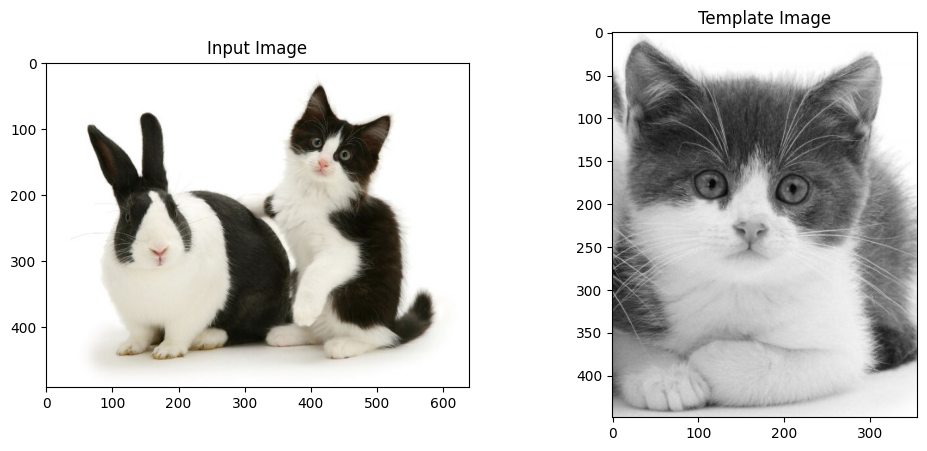

In [2]:
# Membaca gambar input dan template
image_path = '/content/drive/MyDrive/Google Collab/cat-and-rabbit.jpg'
template_path = '/content/drive/MyDrive/Google Collab/cat2_templatejpg.jpg'

img = cv.imread(image_path)
template = cv.imread(template_path)

# Mengubah gambar menjadi grayscale
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

# Menampilkan gambar
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Input Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(template_gray, cmap='gray')
plt.title('Template Image')
plt.axis('on')

plt.show()

In [3]:
# Fungsi untuk melakukan template matching
def template_matching(img, template, method):

    # Melakukan template matching
    result = cv.matchTemplate(img, template, method)

    # Mencari nilai minimum dan maksimum
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(result)

    # Menentukan lokasi terbaik
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    # Mengambil ukuran template
    h, w = template.shape

    # Membuat salinan gambar input
    detected_img = cv.cvtColor(img, cv.COLOR_GRAY2BGR)

    # Membuat kotak merah pada objek yang terdeteksi
    bottom_right = (top_left[0] + w, top_left[1] + h)

    cv.rectangle(
        detected_img,
        top_left,
        bottom_right,
        (0, 0, 255),
        2
    )

    return result, detected_img

In [5]:
# Fungsi untuk menampilkan hasil template matching
def show_result(result, detected_img, method_name):

    plt.figure(figsize=(12, 5))

    # Menampilkan hasil matching
    plt.subplot(1, 2, 1)
    plt.imshow(result, cmap='gray')
    plt.title('Matching Result')
    plt.axis('on')

    # Menampilkan gambar hasil deteksi
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(detected_img, cv.COLOR_BGR2RGB))
    plt.title('Detected Point')
    plt.axis('on')

    plt.suptitle(method_name)
    plt.tight_layout()
    plt.show()

Metode: TM_SQDIFF


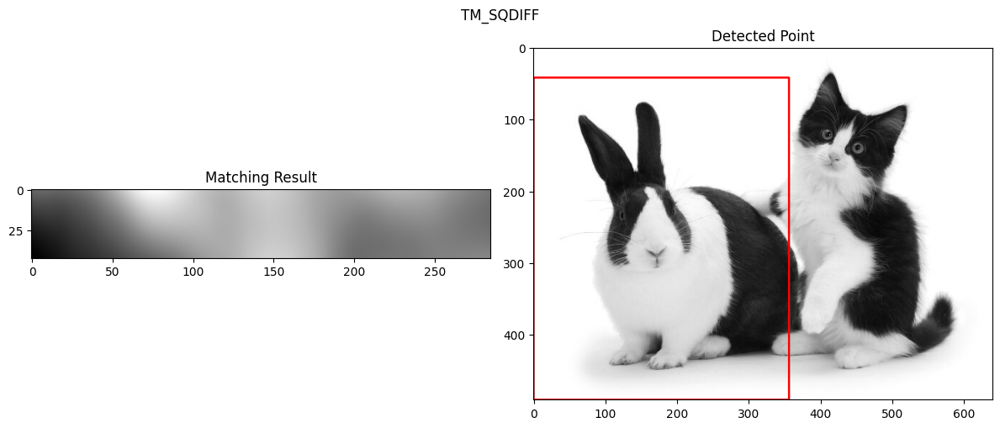

Metode: TM_SQDIFF_NORMED


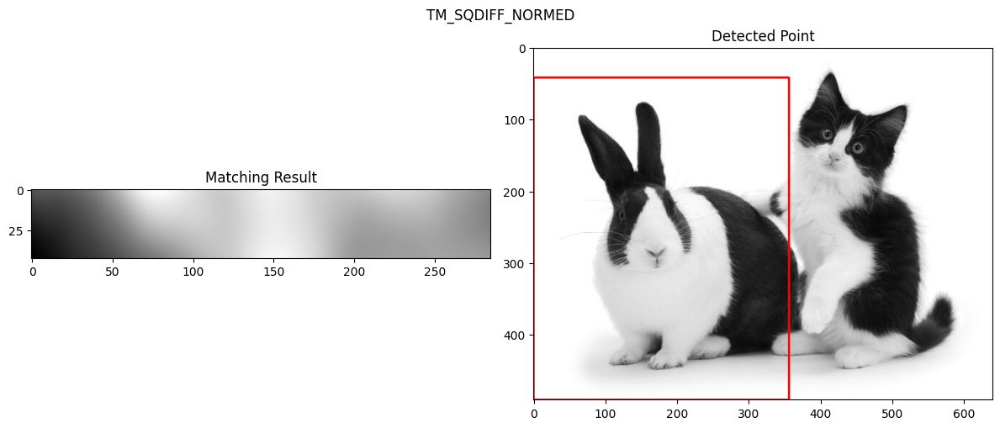

Metode: TM_CCORR


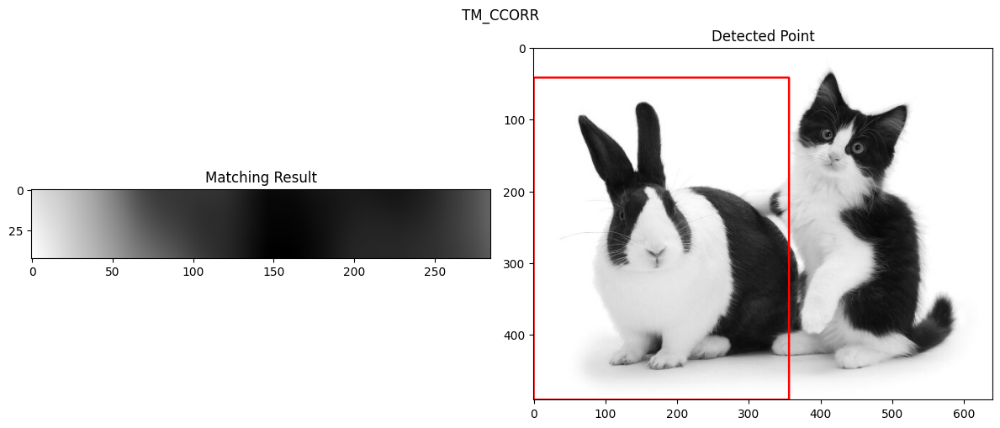

Metode: TM_CCORR_NORMED


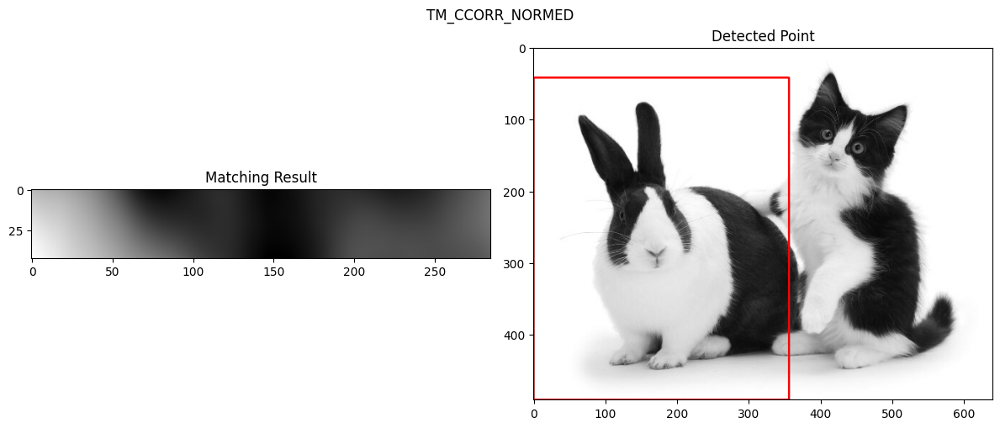

Metode: TM_CCOEFF


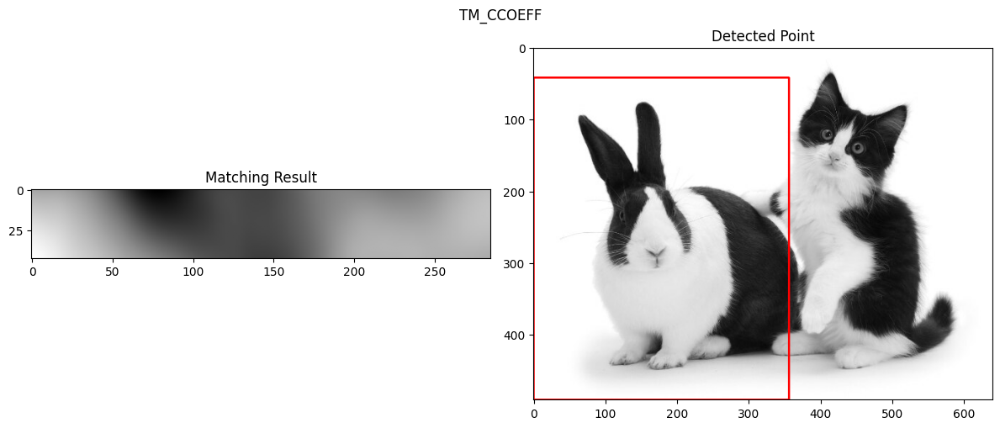

Metode: TM_CCOEFF_NORMED


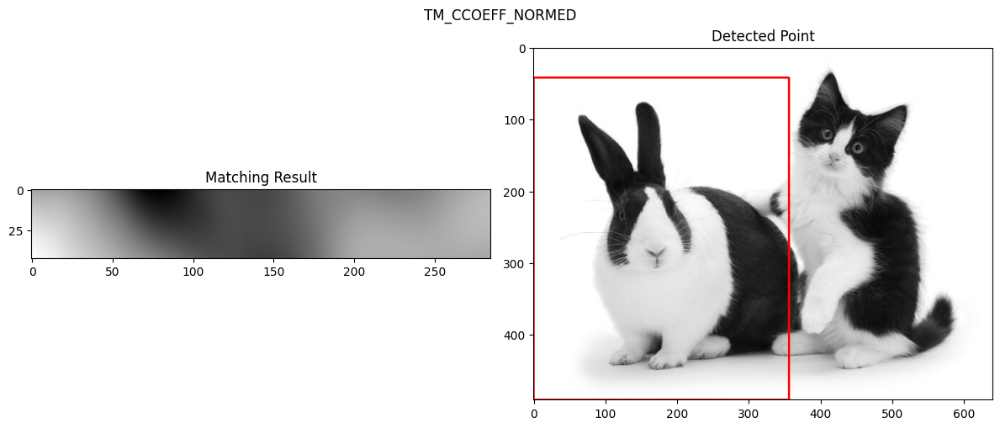

In [6]:
# Daftar enam metode template matching
methods = [
    ('TM_SQDIFF', cv.TM_SQDIFF),
    ('TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED),
    ('TM_CCORR', cv.TM_CCORR),
    ('TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
    ('TM_CCOEFF', cv.TM_CCOEFF),
    ('TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED)
]

# Menjalankan setiap metode
for method_name, method in methods:

    result, detected_img = template_matching(
        img_gray,
        template_gray,
        method
    )

    print('Metode:', method_name)

    show_result(
        result,
        detected_img,
        method_name
    )

Implementasikan konsep template matching tanpa menggunakan library OpenCV untuk multiple object, menggunakan gambar bahrain.jpg untuk citra masukan dan bahraintemplate.jpg sebagai citra template, sehingga menghasilkan output sebagai berikut:

In [7]:
# Import library yang dibutuhkan
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from scipy.signal import fftconvolve
from scipy.ndimage import maximum_filter

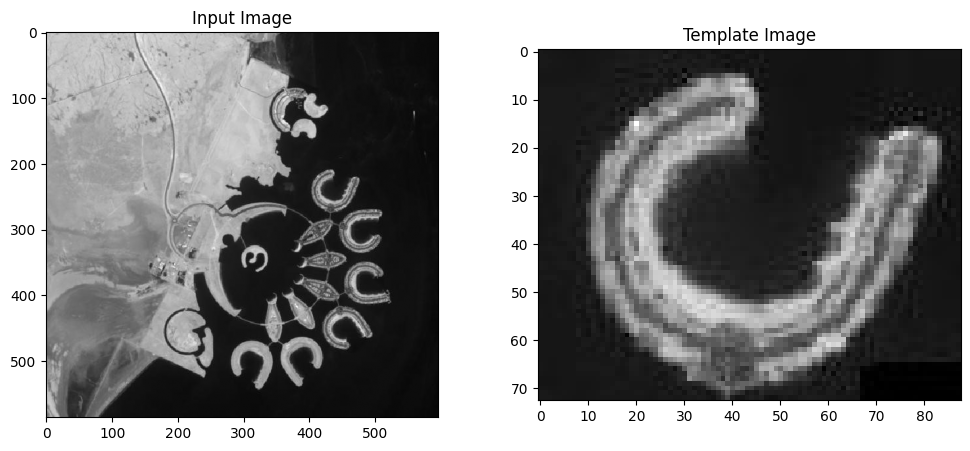

In [9]:
# Membaca gambar input dan template
image_path = '/content/drive/MyDrive/Google Collab/bahrain.jpg'
template_path = '/content/drive/MyDrive/Google Collab/bahrain-template.jpg'

img = np.array(Image.open(image_path).convert('L'))
template = np.array(Image.open(template_path).convert('L'))

# Menampilkan gambar
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Input Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('Template Image')
plt.axis('on')

plt.show()

In [10]:
# Fungsi menghitung normalized cross-correlation
def template_matching(image, template):

    image = image.astype(np.float64)
    template = template.astype(np.float64)

    h, w = template.shape
    n = h * w

    # Menghitung rata-rata template
    template_mean = np.mean(template)

    # Normalisasi template
    template_centered = template - template_mean

    # Menghitung energi template
    template_energy = np.sum(template_centered ** 2)

    # Menghitung korelasi antara gambar dan template
    correlation = fftconvolve(
        image,
        template_centered[::-1, ::-1],
        mode='valid'
    )

    # Menghitung jumlah piksel pada setiap area
    integral = np.pad(
        image.cumsum(axis=0).cumsum(axis=1),
        ((1, 0), (1, 0))
    )

    integral_sq = np.pad(
        (image ** 2).cumsum(axis=0).cumsum(axis=1),
        ((1, 0), (1, 0))
    )

    window_sum = (
        integral[h:, w:] -
        integral[:-h, w:] -
        integral[h:, :-w] +
        integral[:-h, :-w]
    )

    window_sq = (
        integral_sq[h:, w:] -
        integral_sq[:-h, w:] -
        integral_sq[h:, :-w] +
        integral_sq[:-h, :-w]
    )

    # Menghitung normalisasi
    window_energy = window_sq - (window_sum ** 2 / n)

    denominator = np.sqrt(
        np.maximum(template_energy * window_energy, 1e-10)
    )

    # Menghitung nilai kemiripan
    result = correlation / denominator

    return result

In [11]:
# Fungsi untuk memutar template
def rotate_template(template, angle):

    rotated = Image.fromarray(template).rotate(
        angle,
        resample=Image.Resampling.BICUBIC,
        expand=True,
        fillcolor=0
    )

    return np.array(rotated)

In [12]:
# Fungsi untuk mendeteksi multiple object
def detect_multiple_objects(image, template, threshold=0.55):

    detections = []

    # Mencoba template dengan berbagai rotasi
    for angle in range(0, 360, 15):

        rotated = rotate_template(template, angle)

        h, w = rotated.shape

        # Memastikan template tidak lebih besar dari gambar
        if h > image.shape[0] or w > image.shape[1]:
            continue

        # Melakukan template matching
        result = template_matching(image, rotated)

        # Mencari area dengan nilai kemiripan tertinggi
        local_max = maximum_filter(
            result,
            size=(max(3, h // 3), max(3, w // 3))
        )

        # Mengambil titik yang merupakan maksimum lokal
        points = np.where(
            (result >= threshold) &
            (result == local_max)
        )

        # Menyimpan lokasi objek yang ditemukan
        for y, x in zip(points[0], points[1]):

            detections.append({
                'x': int(x),
                'y': int(y),
                'w': int(w),
                'h': int(h),
                'score': float(result[y, x]),
                'angle': angle
            })

    return detections

In [13]:
# Fungsi menghitung Intersection over Union
def calculate_iou(box1, box2):

    x1 = max(box1['x'], box2['x'])
    y1 = max(box1['y'], box2['y'])

    x2 = min(
        box1['x'] + box1['w'],
        box2['x'] + box2['w']
    )

    y2 = min(
        box1['y'] + box1['h'],
        box2['y'] + box2['h']
    )

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = box1['w'] * box1['h']
    area2 = box2['w'] * box2['h']

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


# Fungsi menghilangkan deteksi yang bertumpuk
def non_max_suppression(detections, iou_threshold=0.2):

    # Mengurutkan berdasarkan skor tertinggi
    detections = sorted(
        detections,
        key=lambda x: x['score'],
        reverse=True
    )

    selected = []

    for detection in detections:

        overlap = False

        for chosen in selected:

            if calculate_iou(detection, chosen) > iou_threshold:
                overlap = True
                break

        if not overlap:
            selected.append(detection)

    return selected

In [14]:
# Mendeteksi semua objek yang cocok
detections = detect_multiple_objects(
    img,
    template,
    threshold=0.55
)

# Menghilangkan deteksi yang bertumpuk
final_detections = non_max_suppression(
    detections,
    iou_threshold=0.2
)

print("Jumlah objek terdeteksi:", len(final_detections))

Jumlah objek terdeteksi: 6


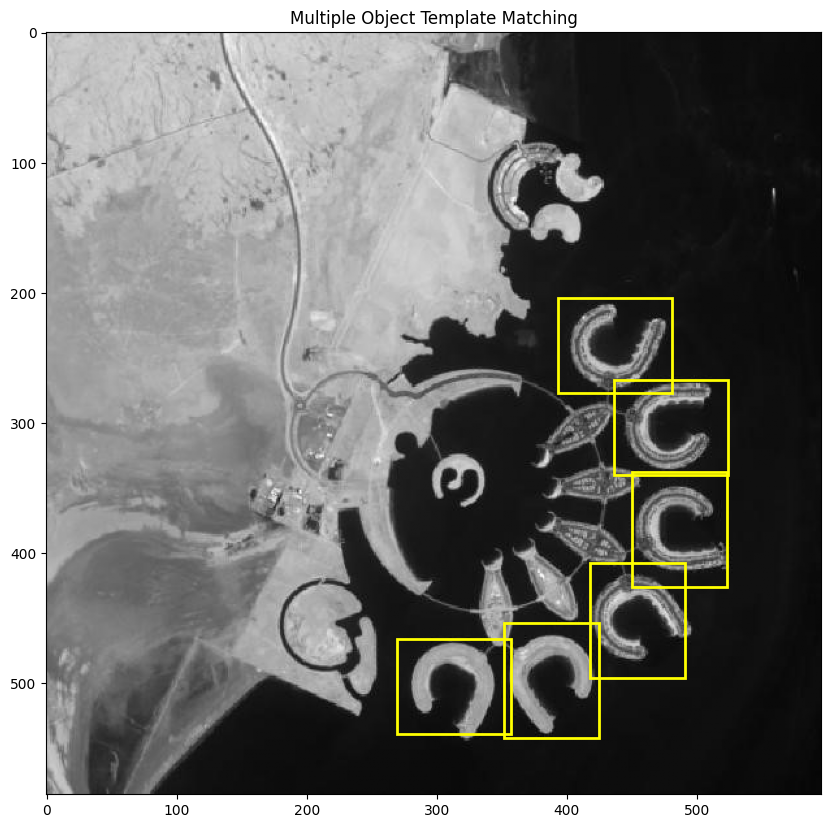

In [15]:
# Menampilkan hasil deteksi
fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(img, cmap='gray')
ax.set_title('Multiple Object Template Matching')

# Menggambar kotak pada setiap objek
for detection in final_detections:

    x = detection['x']
    y = detection['y']
    w = detection['w']
    h = detection['h']

    rectangle = plt.Rectangle(
        (x, y),
        w,
        h,
        linewidth=2,
        edgecolor='yellow',
        facecolor='none'
    )

    ax.add_patch(rectangle)

plt.show()

In [16]:
# Menampilkan informasi setiap objek
for i, detection in enumerate(final_detections):

    print(f"Objek ke-{i + 1}")
    print(f"Posisi X     : {detection['x']}")
    print(f"Posisi Y     : {detection['y']}")
    print(f"Similarity   : {detection['score']:.4f}")
    print(f"Rotasi       : {detection['angle']} derajat")
    print("-----------------------------")

Objek ke-1
Posisi X     : 393
Posisi Y     : 204
Similarity   : 0.9642
Rotasi       : 0 derajat
-----------------------------
Objek ke-2
Posisi X     : 269
Posisi Y     : 466
Similarity   : 0.7107
Rotasi       : 180 derajat
-----------------------------
Objek ke-3
Posisi X     : 418
Posisi Y     : 408
Similarity   : 0.6980
Rotasi       : 270 derajat
-----------------------------
Objek ke-4
Posisi X     : 352
Posisi Y     : 454
Similarity   : 0.6302
Rotasi       : 270 derajat
-----------------------------
Objek ke-5
Posisi X     : 450
Posisi Y     : 338
Similarity   : 0.6265
Rotasi       : 270 derajat
-----------------------------
Objek ke-6
Posisi X     : 436
Posisi Y     : 267
Similarity   : 0.5762
Rotasi       : 0 derajat
-----------------------------


Implementasikan metode Sobel Edge Detection, Canny Edge Detection, dan Laplacian Edge Detection pada OpenCV dengan menggunakan gambar car-park.jpg, sehingga menghasilkan luaran sebagai berikut:

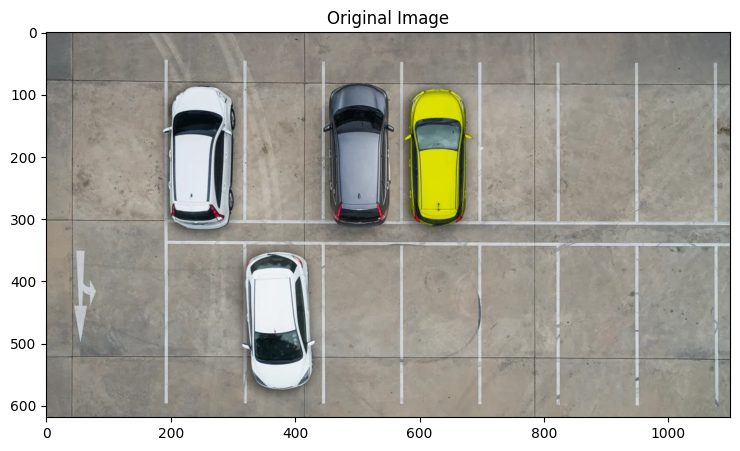

In [17]:
# Membaca gambar
image_path = '/content/drive/MyDrive/Google Collab/car-park.jpg'

img = cv.imread(image_path)

# Mengubah gambar menjadi grayscale
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Menampilkan gambar asli
plt.figure(figsize=(10, 5))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.show()

In [18]:
# Fungsi Sobel Edge Detection
def sobel_edge_detection(img):

    # Deteksi tepi arah horizontal
    sobel_x = cv.Sobel(
        img,
        cv.CV_64F,
        1,
        0,
        ksize=3
    )

    # Deteksi tepi arah vertikal
    sobel_y = cv.Sobel(
        img,
        cv.CV_64F,
        0,
        1,
        ksize=3
    )

    # Mengubah hasil menjadi format 8-bit
    abs_x = cv.convertScaleAbs(sobel_x)
    abs_y = cv.convertScaleAbs(sobel_y)

    # Menggabungkan hasil horizontal dan vertikal
    sobel_result = cv.addWeighted(
        abs_x, 0.5,
        abs_y, 0.5,
        0
    )

    return sobel_result

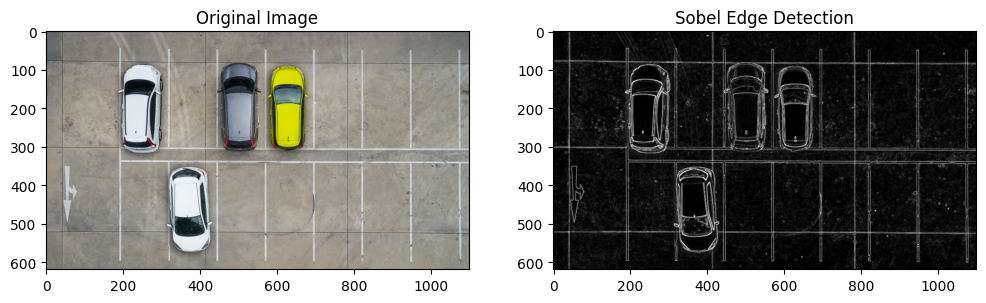

In [19]:
# Menjalankan Sobel Edge Detection
sobel_result = sobel_edge_detection(img_gray)

# Menampilkan hasil
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(sobel_result, cmap='gray')
plt.title('Sobel Edge Detection')
plt.axis('on')

plt.show()

In [20]:
# Fungsi Canny Edge Detection
def canny_edge_detection(img):

    # Mengurangi noise menggunakan Gaussian Blur
    blurred = cv.GaussianBlur(
        img,
        (5, 5),
        0
    )

    # Melakukan Canny Edge Detection
    canny_result = cv.Canny(
        blurred,
        50,
        150
    )

    return canny_result

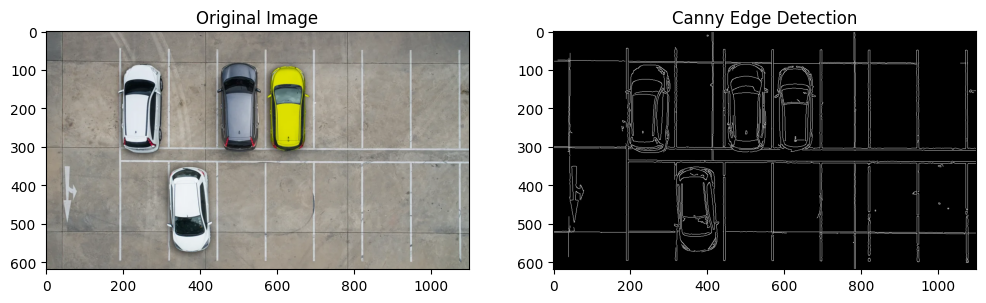

In [21]:
# Menjalankan Canny Edge Detection
canny_result = canny_edge_detection(img_gray)

# Menampilkan hasil
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(canny_result, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('on')

plt.show()

In [22]:
# Fungsi Laplacian Edge Detection
def laplacian_edge_detection(img):

    # Melakukan Gaussian Blur untuk mengurangi noise
    blurred = cv.GaussianBlur(
        img,
        (3, 3),
        0
    )

    # Melakukan Laplacian Edge Detection
    laplacian = cv.Laplacian(
        blurred,
        cv.CV_64F,
        ksize=3
    )

    # Mengubah hasil menjadi format 8-bit
    laplacian_result = cv.convertScaleAbs(
        laplacian
    )

    return laplacian_result

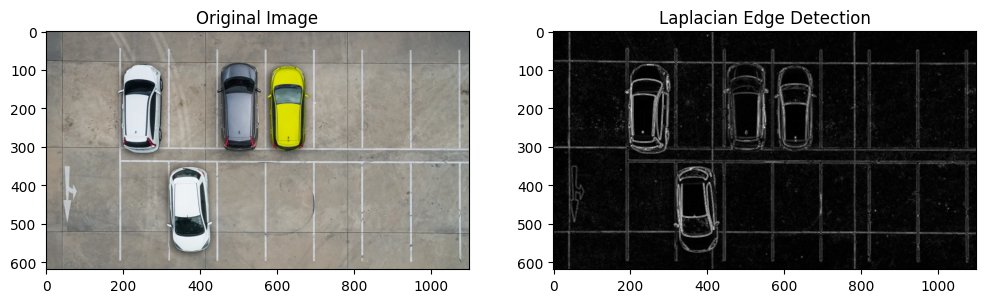

In [23]:
# Menjalankan Laplacian Edge Detection
laplacian_result = laplacian_edge_detection(img_gray)

# Menampilkan hasil
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(laplacian_result, cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('on')

plt.show()

Implementasikan metode Harris Corner Detection dan Shi-Tomasi Detection pada OpenCV dengan menggunakan gambar chessboard.jpg, sehingga menghasilkan luaran sebagai berikut:

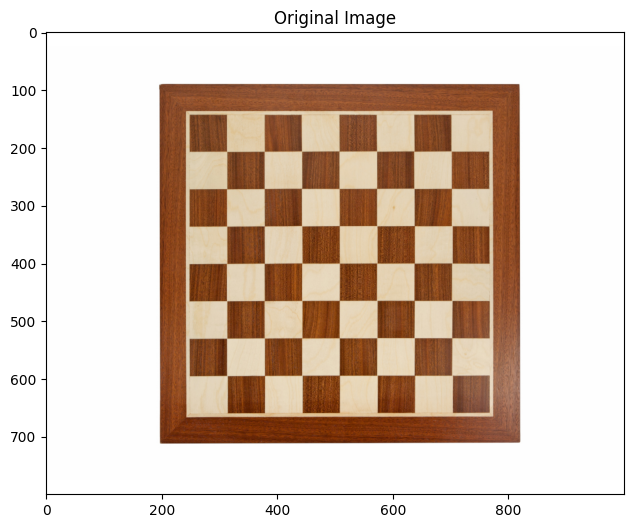

In [24]:
# Membaca gambar
image_path = '/content/drive/MyDrive/Google Collab/chess-board.jpg'

img = cv.imread(image_path)

# Mengubah gambar menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Mengubah grayscale menjadi float32
gray = np.float32(gray)

# Menampilkan gambar
plt.figure(figsize=(8, 6))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.show()

In [25]:
# Fungsi Harris Corner Detection
def harris_corner_detection(img):

    # Mengubah gambar menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Mengubah gambar menjadi float32
    gray = np.float32(gray)

    # Melakukan Harris Corner Detection
    harris = cv.cornerHarris(
        gray,
        blockSize=2,
        ksize=3,
        k=0.04
    )

    # Memperbesar area sudut yang terdeteksi
    harris = cv.dilate(harris, None)

    # Membuat salinan gambar
    result = img.copy()

    # Menandai titik sudut dengan warna merah
    result[harris > 0.01 * harris.max()] = [0, 0, 255]

    return result, harris

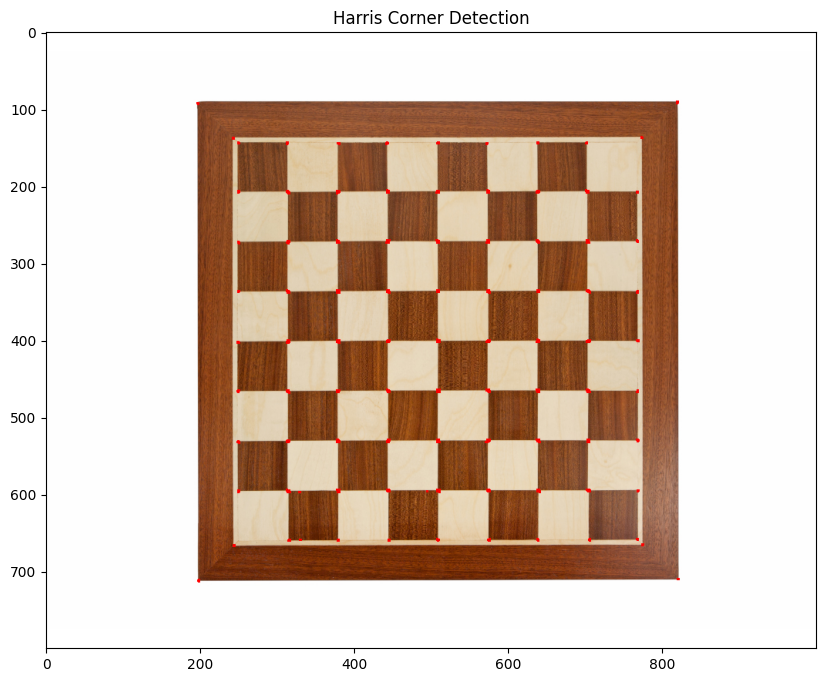

In [26]:
# Menjalankan Harris Corner Detection
harris_result, harris_response = harris_corner_detection(img)

# Menampilkan hasil
plt.figure(figsize=(10, 8))

plt.imshow(cv.cvtColor(harris_result, cv.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('on')

plt.show()

In [27]:
# Fungsi Shi-Tomasi Detection
def shi_tomasi_detection(img):

    # Mengubah gambar menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Mendeteksi titik sudut menggunakan Shi-Tomasi
    corners = cv.goodFeaturesToTrack(
        gray,
        maxCorners=100,
        qualityLevel=0.01,
        minDistance=10
    )

    # Membuat salinan gambar
    result = img.copy()

    # Menandai titik sudut dengan warna biru
    if corners is not None:

        corners = np.int32(corners)

        for corner in corners:

            x, y = corner.ravel()

            cv.circle(
                result,
                (x, y),
                3,
                (255, 0, 0),
                -1
            )

    return result, corners

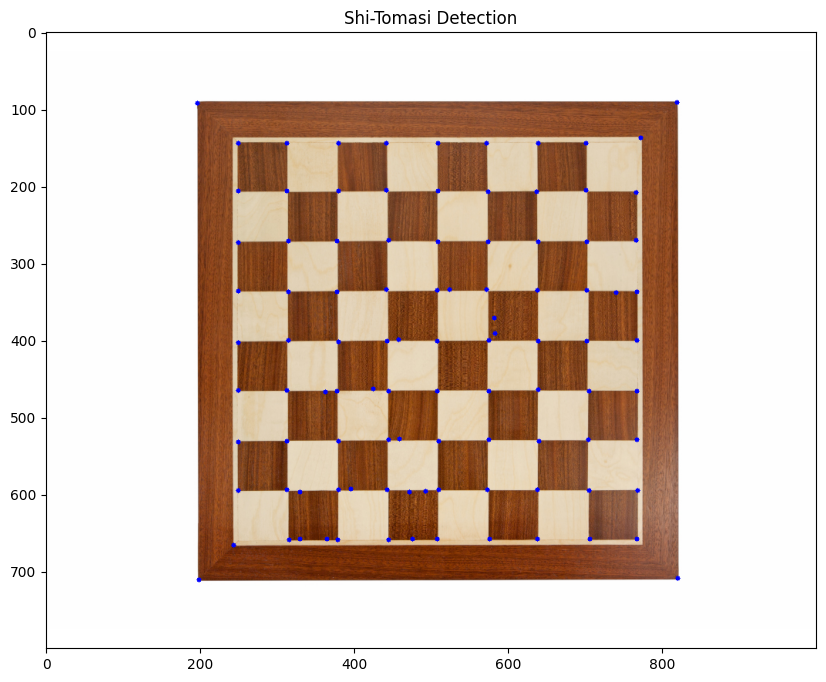

In [28]:
# Menjalankan Shi-Tomasi Detection
shi_result, shi_corners = shi_tomasi_detection(img)

# Menampilkan hasil
plt.figure(figsize=(10, 8))

plt.imshow(cv.cvtColor(shi_result, cv.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Detection')
plt.axis('on')

plt.show()

In [29]:
# Menghitung jumlah titik sudut
harris_count = np.sum(
    harris_response > 0.01 * harris_response.max()
)

shi_count = len(shi_corners) if shi_corners is not None else 0

print("Harris Corner Detection")
print("Jumlah titik sudut:", harris_count)

print("\nShi-Tomasi Detection")
print("Jumlah titik sudut:", shi_count)

Harris Corner Detection
Jumlah titik sudut: 2238

Shi-Tomasi Detection
Jumlah titik sudut: 100


Implementasikan metode Hough Transform pada OpenCV dengan menggunakan gambar sudoku.jpg. Tahapan proses grid detection sesuai yang terdapat pada ulasan teori, sehingga menghasilkan luaran sebagai berikut:

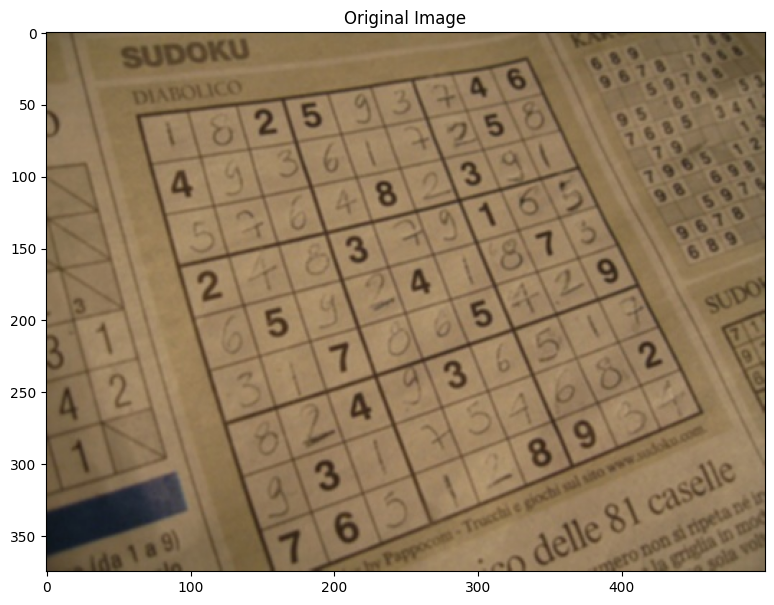

In [30]:
# Membaca gambar
image_path = '/content/drive/MyDrive/Google Collab/sudoku.jpg'

img = cv.imread(image_path)

# Mengubah gambar menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Menampilkan gambar asli
plt.figure(figsize=(10, 7))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.show()

In [31]:
# Fungsi preprocessing gambar
def preprocessing_image(gray):

    # Mengurangi noise menggunakan Gaussian Blur
    blurred = cv.GaussianBlur(
        gray,
        (5, 5),
        1
    )

    # Mendeteksi tepi menggunakan Canny
    edges = cv.Canny(
        blurred,
        50,
        150
    )

    return edges

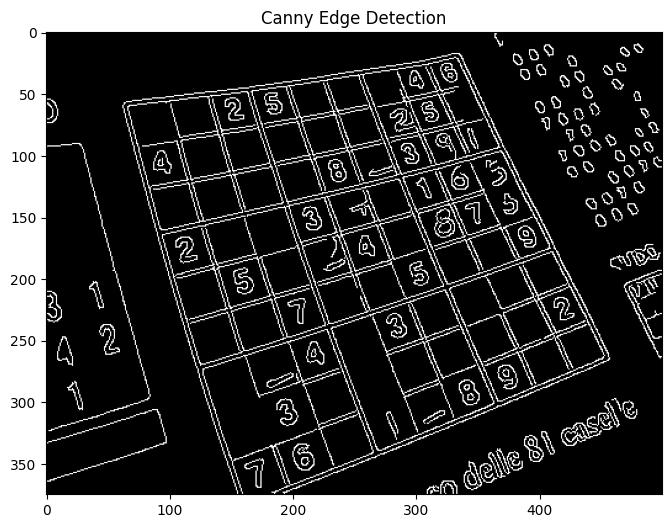

In [32]:
# Menjalankan preprocessing
edges = preprocessing_image(gray)

# Menampilkan hasil
plt.figure(figsize=(10, 6))

plt.imshow(edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('on')

plt.show()

In [33]:
# Fungsi Hough Transform
def hough_transform(edges):

    # Mendeteksi garis menggunakan Hough Line Transform
    lines = cv.HoughLinesP(
        edges,
        rho=1,
        theta=np.pi / 180,
        threshold=80,
        minLineLength=50,
        maxLineGap=20
    )

    return lines

In [34]:
# Fungsi menggambar garis hasil Hough Transform
def draw_hough_lines(img, lines):

    # Membuat salinan gambar
    result = img.copy()

    # Memeriksa apakah garis berhasil ditemukan
    if lines is not None:

        for line in lines:

            x1, y1, x2, y2 = line[0]

            # Menggambar garis berwarna merah
            cv.line(
                result,
                (x1, y1),
                (x2, y2),
                (0, 0, 255),
                2
            )

    return result

In [35]:
# Mendeteksi garis menggunakan Hough Transform
lines = hough_transform(edges)

# Menggambar garis pada gambar asli
result = draw_hough_lines(img, lines)

# Menampilkan jumlah garis terdeteksi
if lines is not None:
    print("Jumlah garis terdeteksi:", len(lines))
else:
    print("Tidak ada garis yang terdeteksi")

Jumlah garis terdeteksi: 66


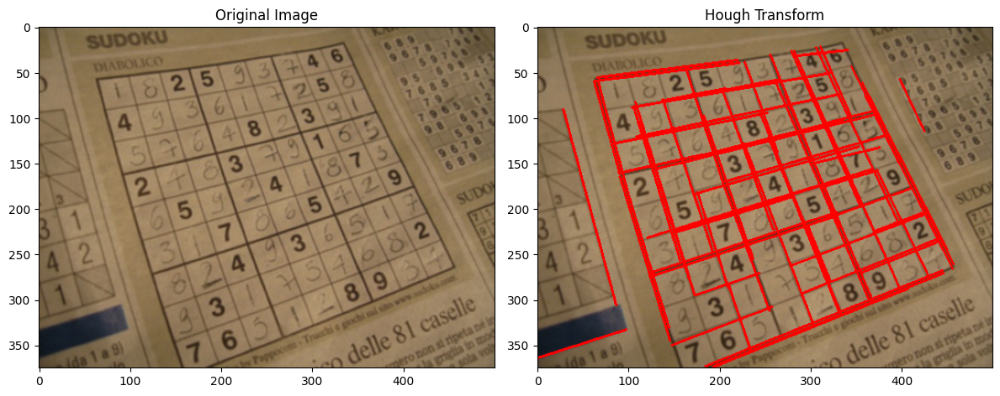

In [36]:
# Menampilkan hasil Hough Transform
plt.figure(figsize=(12, 8))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Hough Transform')
plt.axis('on')

plt.tight_layout()
plt.show()

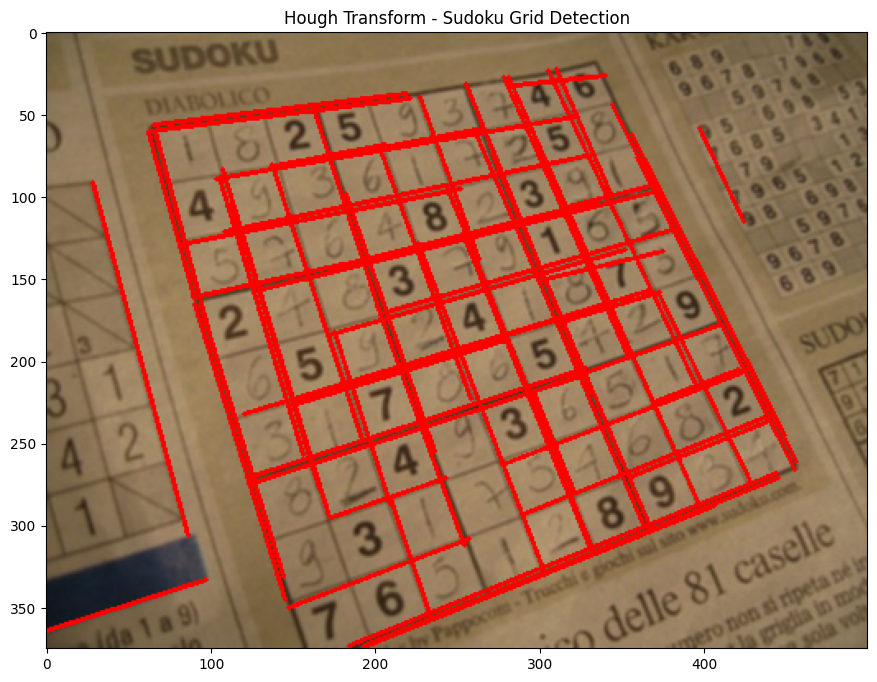

In [37]:
# Menampilkan hasil akhir
plt.figure(figsize=(12, 8))

plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Hough Transform - Sudoku Grid Detection')
plt.axis('on')

plt.show()

Implementasikan fungsi findContours() pada OpenCV untuk contour detection dengan menggunakan gambar laptop.jpg, sehingga menghasilkan luaran sebagai berikut:

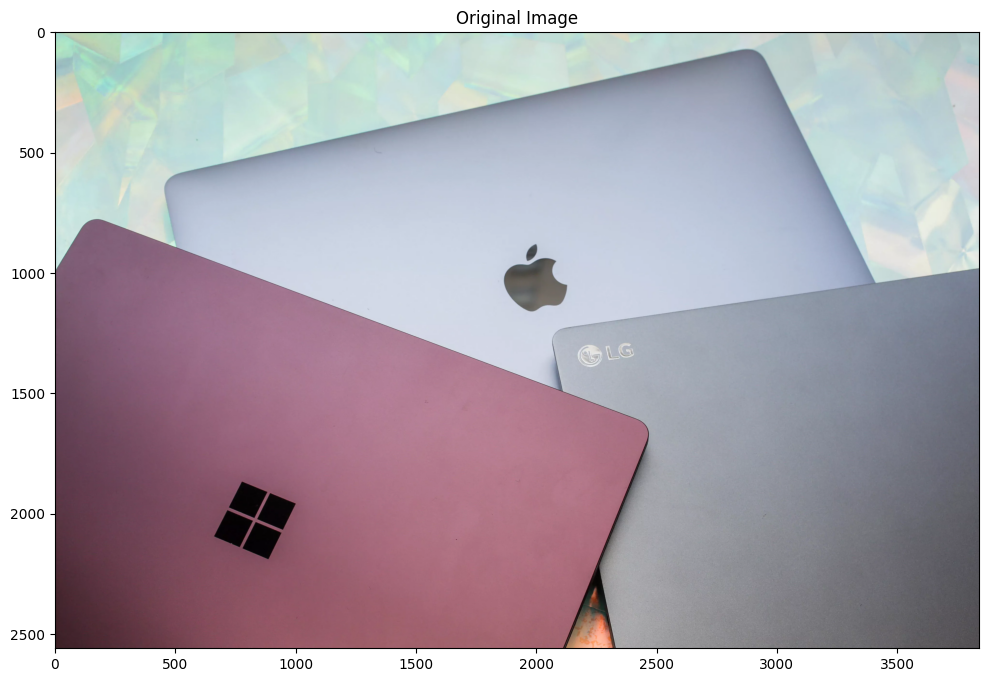

In [38]:
# Membaca gambar
image_path = '/content/drive/MyDrive/Google Collab/laptop.jpg'

img = cv.imread(image_path)

# Mengubah gambar menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Menampilkan gambar asli
plt.figure(figsize=(12, 8))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.show()

In [39]:
# Fungsi preprocessing gambar
def preprocessing_image(gray):

    # Mengurangi noise menggunakan Gaussian Blur
    blurred = cv.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    # Mendeteksi tepi menggunakan Canny
    edges = cv.Canny(
        blurred,
        50,
        150
    )

    return edges

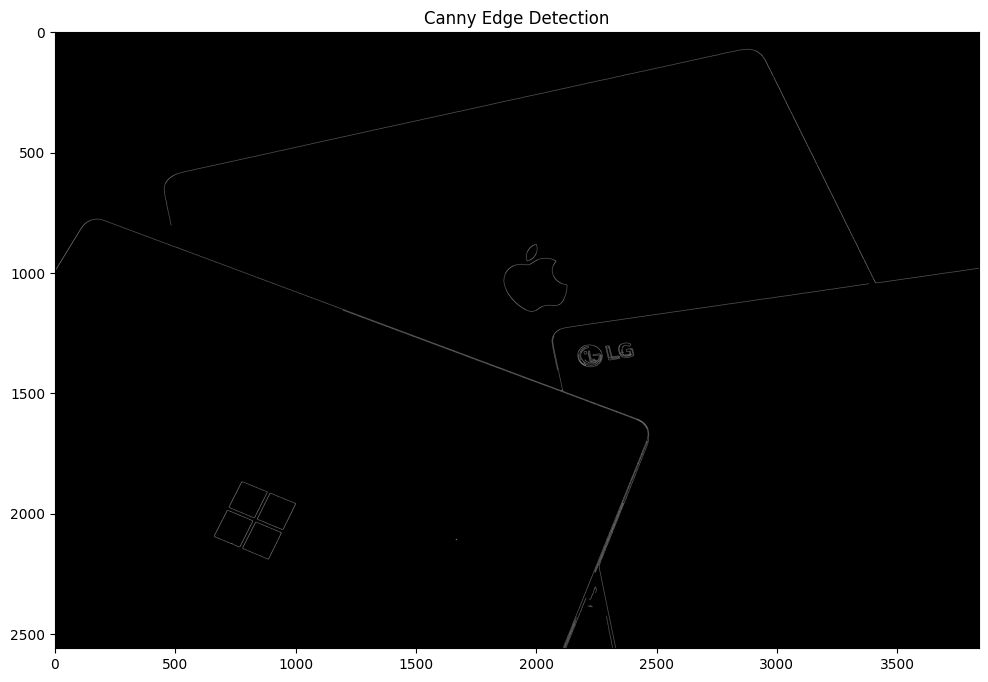

In [40]:
# Menjalankan preprocessing
edges = preprocessing_image(gray)

# Menampilkan hasil
plt.figure(figsize=(12, 8))

plt.imshow(edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('on')

plt.show()

In [41]:
# Fungsi Contour Detection
def contour_detection(edges):

    # Menemukan contour pada gambar
    contours, hierarchy = cv.findContours(
        edges,
        cv.RETR_EXTERNAL,
        cv.CHAIN_APPROX_SIMPLE
    )

    return contours, hierarchy

In [42]:
# Fungsi menggambar contour
def draw_contours(img, contours):

    # Membuat salinan gambar
    result = img.copy()

    # Menggambar semua contour dengan warna merah
    cv.drawContours(
        result,
        contours,
        -1,
        (0, 0, 255),
        2
    )

    return result

In [43]:
# Mendeteksi contour
contours, hierarchy = contour_detection(edges)

# Menampilkan jumlah contour
print("Jumlah contour terdeteksi:", len(contours))

# Menggambar contour pada gambar asli
result = draw_contours(img, contours)

Jumlah contour terdeteksi: 28


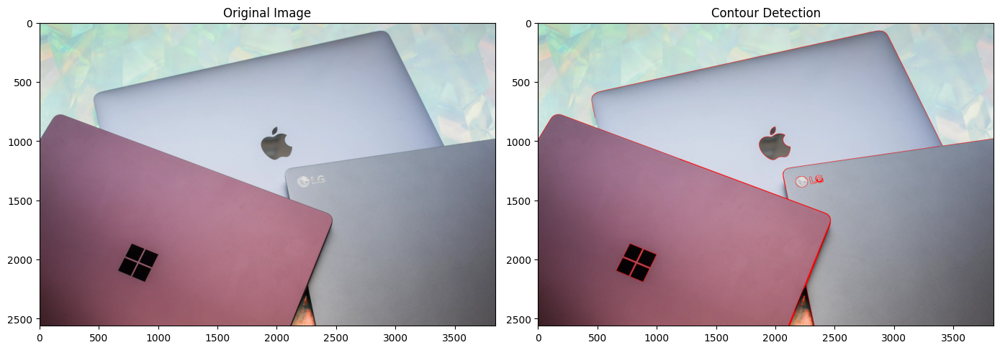

In [44]:
# Menampilkan hasil Contour Detection
plt.figure(figsize=(14, 8))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Contour Detection')
plt.axis('on')

plt.tight_layout()
plt.show()

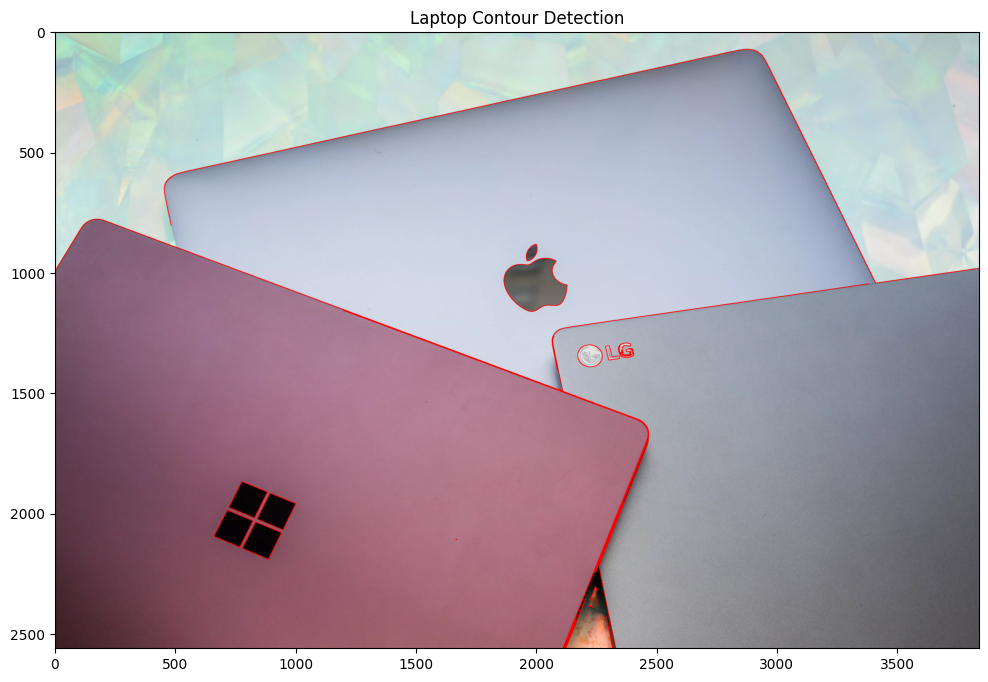

In [45]:
# Menampilkan gambar hasil contour detection
plt.figure(figsize=(14, 8))

plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Laptop Contour Detection')
plt.axis('on')

plt.show()

 Lakukan Face Detection untuk image object lain yang tersedia pada (/images/facedet). Tampilkan seperti pada contoh berikut.

In [46]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

In [47]:
# Menentukan folder gambar
folder_path = '/content/drive/MyDrive/Google Collab/facedet'

# Mengambil semua file gambar
image_paths = []

for ext in ['*.jpg', '*.jpeg', '*.png']:
    image_paths.extend(
        glob.glob(os.path.join(folder_path, ext))
    )

# Menampilkan daftar gambar
print("Jumlah gambar:", len(image_paths))

for path in image_paths:
    print(os.path.basename(path))

Jumlah gambar: 8
kucing.jpg
kartini.jpg
mjordan.jpg
many_cereals.jpg
jokowi.jpg
solvayconf.jpg
mask.png
reeses_puffs.png


In [48]:
# Memuat model Haar Cascade
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# Fungsi Face Detection
def face_detection(img):

    # Mengubah gambar menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Mendeteksi wajah
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    # Membuat salinan gambar
    result = img.copy()

    # Menggambar kotak pada wajah yang terdeteksi
    for (x, y, w, h) in faces:

        cv.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    return result, faces

In [49]:
# Fungsi menampilkan hasil Face Detection
def show_result(img, result, filename, faces):

    plt.figure(figsize=(12, 5))

    # Gambar asli
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.axis('on')

    # Gambar hasil deteksi
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title('Face Detection')
    plt.axis('on')

    plt.suptitle(filename)
    plt.tight_layout()
    plt.show()

    print("Nama gambar:", filename)
    print("Jumlah wajah terdeteksi:", len(faces))
    print("-----------------------------")

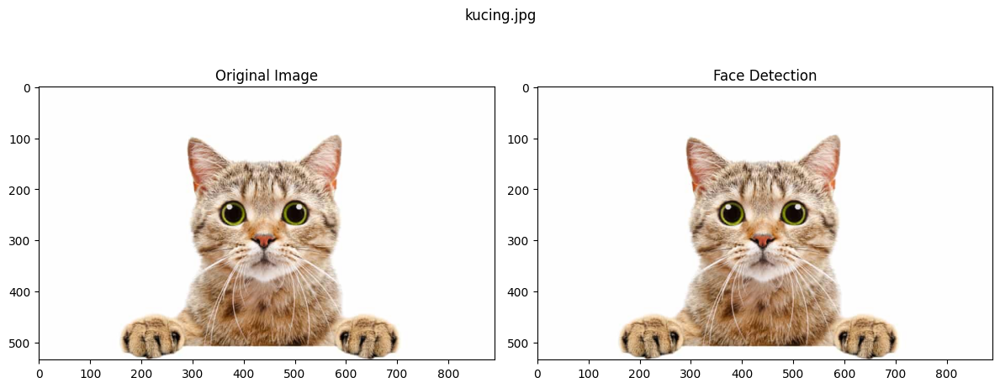

Nama gambar: kucing.jpg
Jumlah wajah terdeteksi: 0
-----------------------------


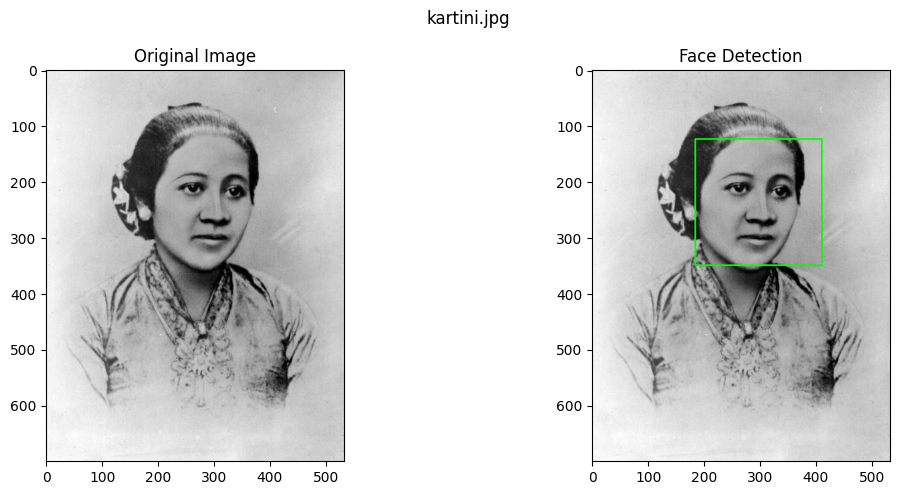

Nama gambar: kartini.jpg
Jumlah wajah terdeteksi: 1
-----------------------------


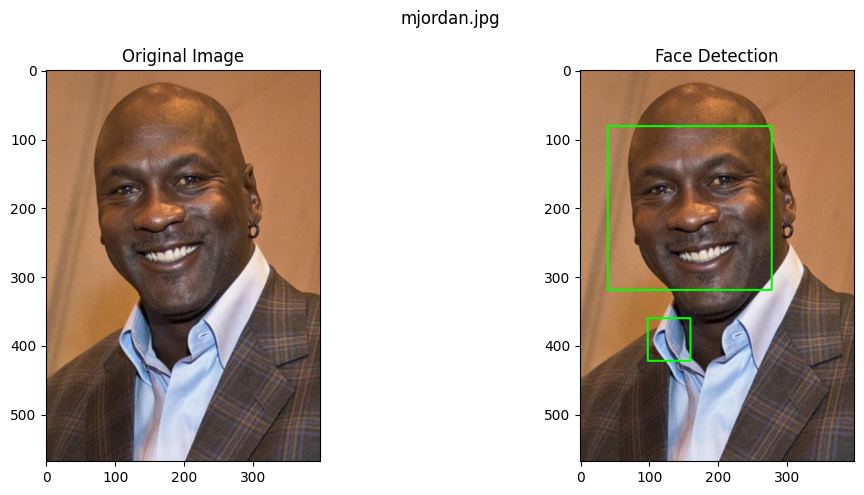

Nama gambar: mjordan.jpg
Jumlah wajah terdeteksi: 2
-----------------------------


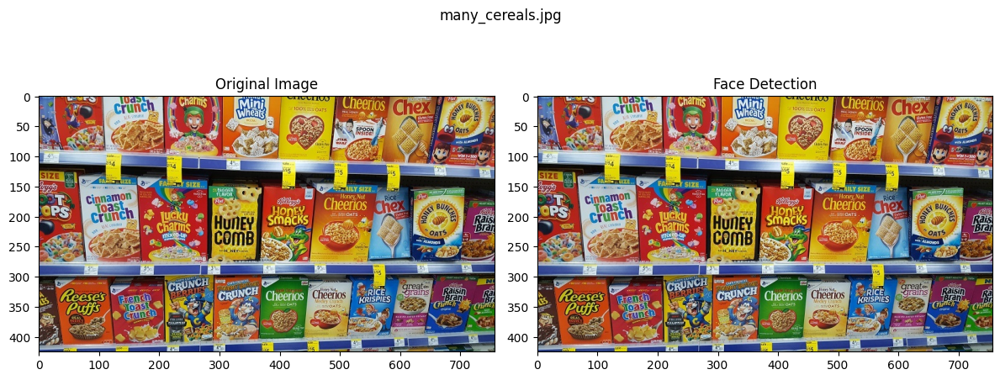

Nama gambar: many_cereals.jpg
Jumlah wajah terdeteksi: 0
-----------------------------


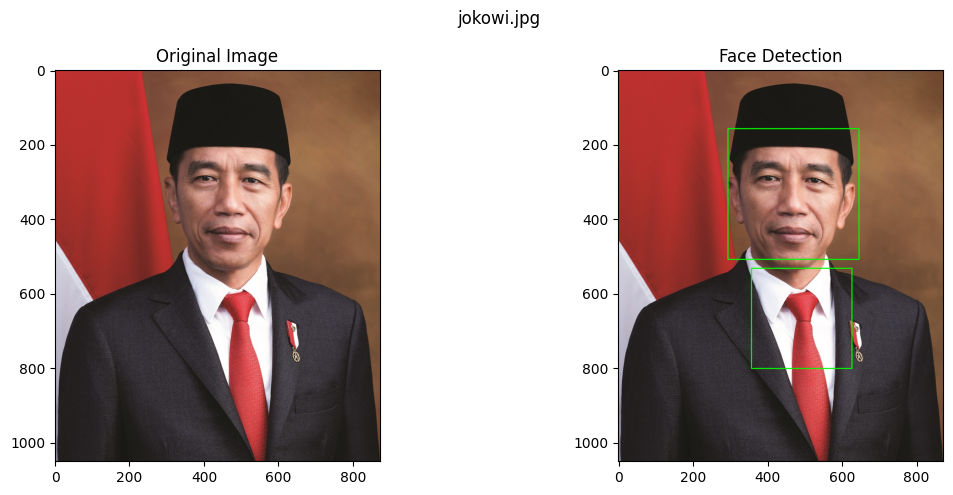

Nama gambar: jokowi.jpg
Jumlah wajah terdeteksi: 2
-----------------------------


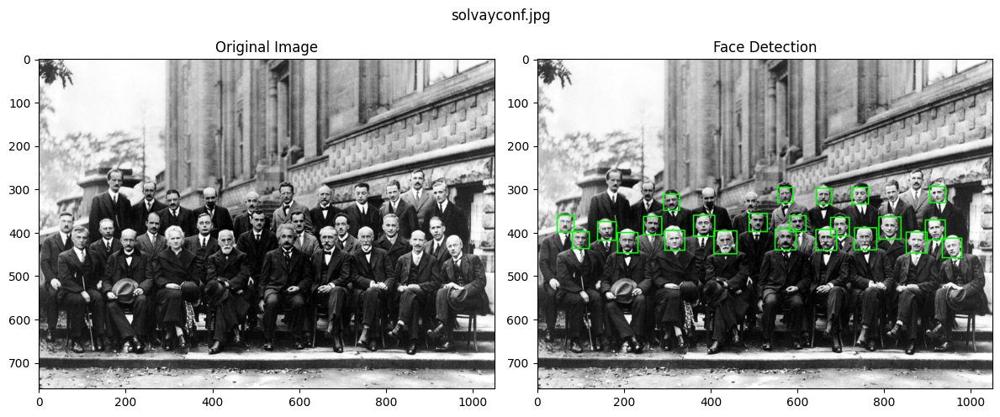

Nama gambar: solvayconf.jpg
Jumlah wajah terdeteksi: 23
-----------------------------


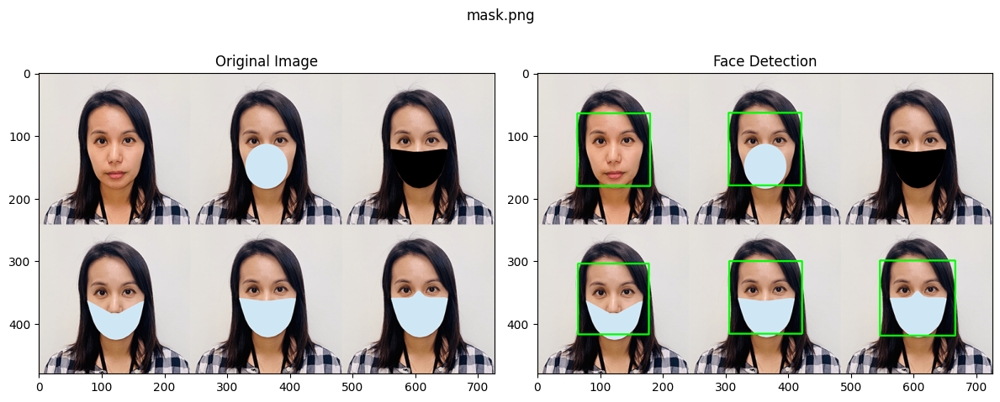

Nama gambar: mask.png
Jumlah wajah terdeteksi: 5
-----------------------------


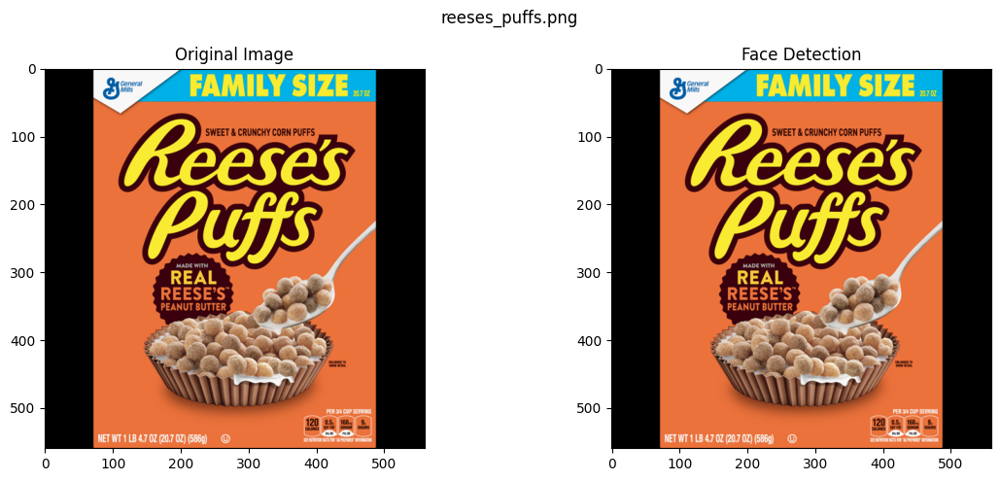

Nama gambar: reeses_puffs.png
Jumlah wajah terdeteksi: 0
-----------------------------


In [50]:
# Menjalankan Face Detection pada semua gambar
for image_path in image_paths:

    # Membaca gambar
    img = cv.imread(image_path)

    if img is None:
        print("Gagal membaca:", image_path)
        continue

    # Melakukan Face Detection
    result, faces = face_detection(img)

    # Menampilkan hasil
    show_result(
        img,
        result,
        os.path.basename(image_path),
        faces
    )

In [52]:
# Membuat folder untuk menyimpan hasil
output_folder = '/content/face_detection_result'

os.makedirs(output_folder, exist_ok=True)

# Menyimpan seluruh hasil deteksi
for image_path in image_paths:

    img = cv.imread(image_path)

    if img is None:
        continue

    result, faces = face_detection(img)

    filename = os.path.basename(image_path)

    output_path = os.path.join(
        output_folder,
        filename
    )

    cv.imwrite(output_path, result)

print("Semua hasil berhasil diproses.")
print("Lokasi penyimpanan:", output_folder)

Semua hasil berhasil diproses.
Lokasi penyimpanan: /content/face_detection_result


 Pada soal sebelumnya, wajah kucing tidak bisa dideteksi dengan baik. Lakukan deteksi wajah kucing hingga muncul rectangle pada bagian wajah kucing. Petunjuk pada soal ini, perhatikan pretrained features yang telah disediakan OpenCV. Gunakan xml yang ada jika memang telah disediakan. Jika belum ada, coba cari dengan searching melalui search engines.

In [54]:
# Import library yang dibutuhkan
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os
import requests

In [55]:
# Menentukan lokasi XML
xml_path = '/content/haarcascade_frontalcatface.xml'

# URL pretrained XML dari repository OpenCV
xml_url = 'https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalcatface.xml'

# Mengunduh XML jika belum tersedia
if not os.path.exists(xml_path):

    response = requests.get(xml_url)
    response.raise_for_status()

    with open(xml_path, 'wb') as file:
        file.write(response.content)

    print("Pretrained XML berhasil diunduh!")

else:
    print("Pretrained XML sudah tersedia!")

Pretrained XML berhasil diunduh!


In [56]:
# Memuat model Haar Cascade khusus wajah kucing
cat_face_cascade = cv.CascadeClassifier(xml_path)

# Memeriksa apakah model berhasil dimuat
if cat_face_cascade.empty():
    raise ValueError("Gagal memuat pretrained XML!")

print("Cat Face Classifier berhasil dimuat!")

Cat Face Classifier berhasil dimuat!


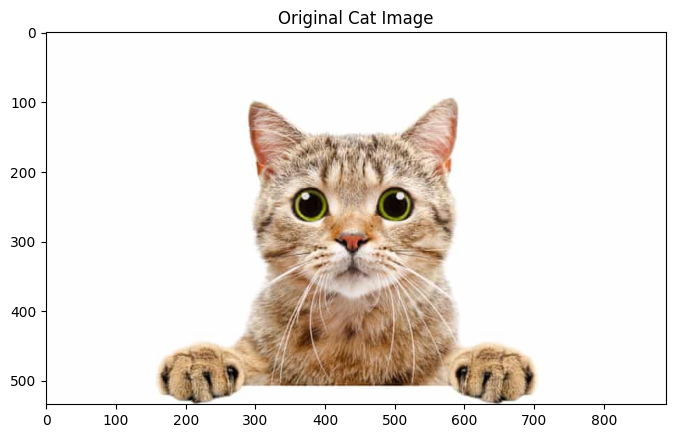

In [57]:
# Membaca gambar kucing
image_path = '/content/drive/MyDrive/Google Collab/facedet/kucing.jpg'

img = cv.imread(image_path)

# Memeriksa gambar
if img is None:
    raise ValueError("Gambar tidak ditemukan!")

# Mengubah gambar menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Menampilkan gambar asli
plt.figure(figsize=(8, 6))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Cat Image')
plt.axis('on')

plt.show()

In [58]:
# Fungsi Cat Face Detection
def cat_face_detection(img):

    # Mengubah gambar menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Meningkatkan kontras gambar
    gray = cv.equalizeHist(gray)

    # Mendeteksi wajah kucing
    faces = cat_face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=3,
        minSize=(30, 30)
    )

    # Membuat salinan gambar
    result = img.copy()

    # Menggambar rectangle pada wajah kucing
    for (x, y, w, h) in faces:

        cv.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (255, 255, 255),
            3
        )

    return result, faces

In [59]:
# Fungsi menampilkan hasil deteksi
def show_result(img, result, faces):

    plt.figure(figsize=(12, 6))

    # Gambar asli
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.axis('on')

    # Gambar hasil deteksi
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title('Cat Face Detection')
    plt.axis('on')

    plt.tight_layout()
    plt.show()

    print("Jumlah wajah kucing terdeteksi:", len(faces))

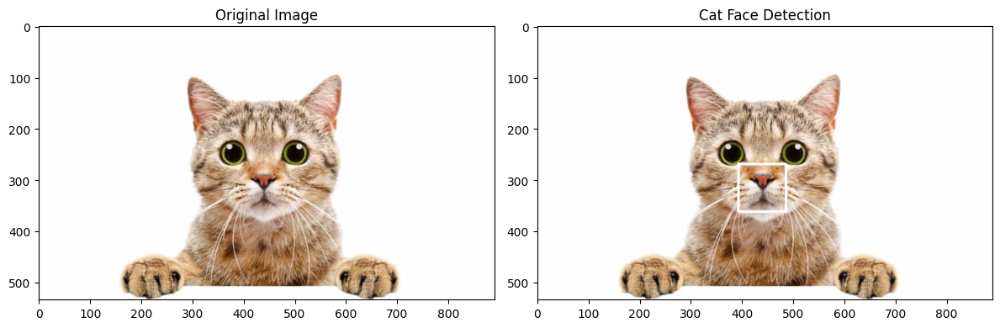

Jumlah wajah kucing terdeteksi: 1


In [60]:
# Menjalankan deteksi wajah kucing
result, faces = cat_face_detection(img)

# Menampilkan hasil deteksi
show_result(img, result, faces)

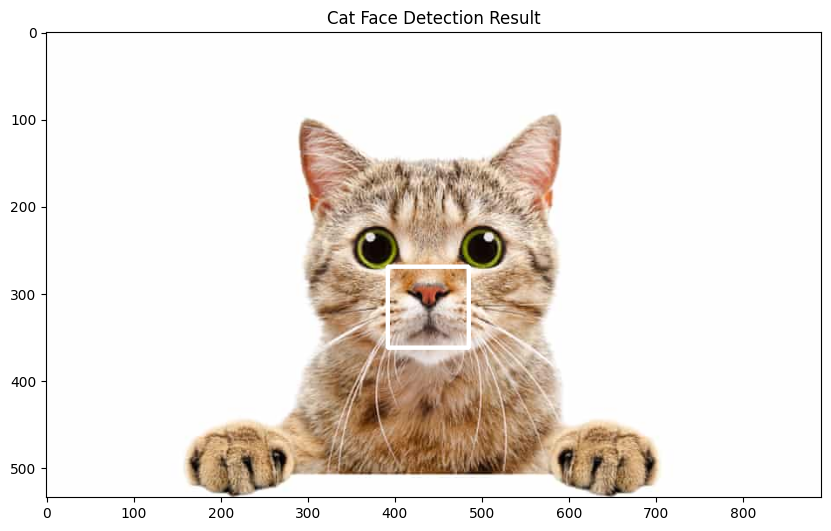

In [61]:
# Menampilkan hasil akhir
plt.figure(figsize=(10, 7))

plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Cat Face Detection Result')
plt.axis('on')

plt.show()

Cobakan juga untuk eyes detection pada wajah Pak Prabowo:

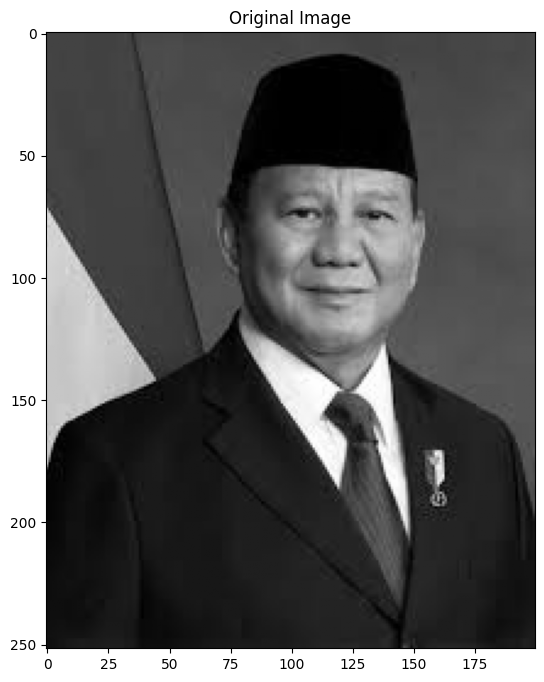

In [62]:
# Membaca gambar
image_path = '/content/drive/MyDrive/Google Collab/Prabowo.jpeg'

img = cv.imread(image_path)

# Memeriksa gambar
if img is None:
    raise ValueError("Gambar tidak ditemukan!")

# Mengubah gambar menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Menampilkan gambar asli
plt.figure(figsize=(7, 8))

plt.imshow(gray, cmap='gray')
plt.title('Original Image')
plt.axis('on')

plt.show()

In [63]:
# Memuat pretrained Haar Cascade untuk wajah
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# Memuat pretrained Haar Cascade untuk mata
eye_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_eye.xml'
)

# Memeriksa model
if face_cascade.empty() or eye_cascade.empty():
    raise ValueError("Gagal memuat Haar Cascade!")

print("Pretrained Haar Cascade berhasil dimuat!")

Pretrained Haar Cascade berhasil dimuat!


In [64]:
# Fungsi Eye Detection
def eye_detection(img):

    # Mengubah gambar menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Mendeteksi wajah
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(50, 50)
    )

    # Membuat salinan gambar
    result = img.copy()

    # Menampung jumlah mata yang terdeteksi
    total_eyes = 0

    # Melakukan deteksi mata pada setiap wajah
    for (x, y, w, h) in faces:

        # Mengambil area wajah
        roi_gray = gray[y:y+h, x:x+w]

        # Mengambil area wajah pada gambar asli
        roi_color = result[y:y+h, x:x+w]

        # Mendeteksi mata pada area wajah
        eyes = eye_cascade.detectMultiScale(
            roi_gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(15, 15)
        )

        # Menggambar rectangle pada mata
        for (ex, ey, ew, eh) in eyes:

            cv.rectangle(
                roi_color,
                (ex, ey),
                (ex + ew, ey + eh),
                (255, 255, 255),
                2
            )

            total_eyes += 1

    return result, faces, total_eyes

In [65]:
# Fungsi menampilkan hasil Eye Detection
def show_result(img, result, total_eyes):

    plt.figure(figsize=(12, 7))

    # Gambar asli
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.axis('on')

    # Gambar hasil deteksi
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title('Eye Detection')
    plt.axis('on')

    plt.tight_layout()
    plt.show()

    print("Jumlah mata terdeteksi:", total_eyes)

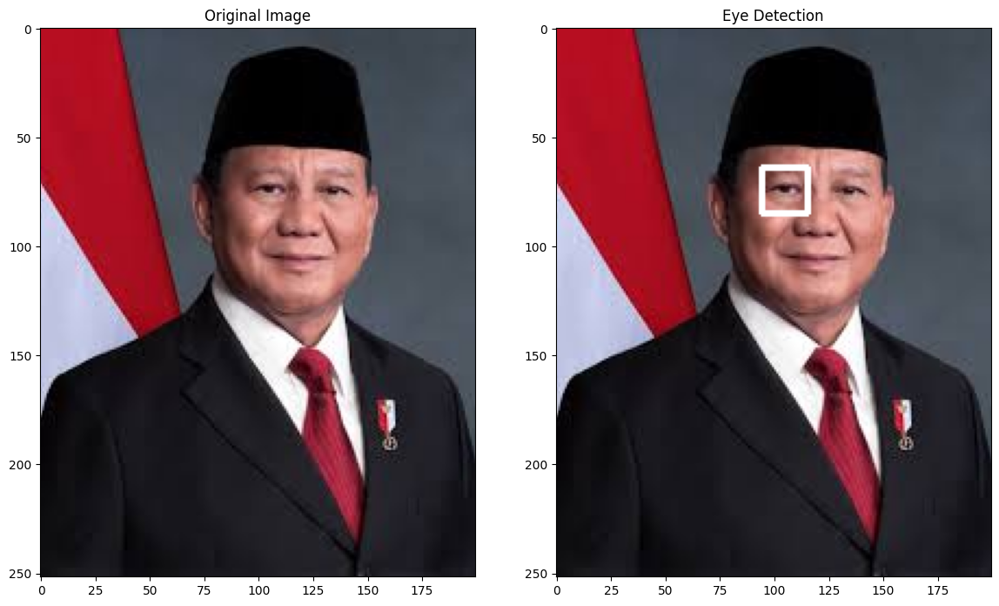

Jumlah mata terdeteksi: 1


In [66]:
# Menjalankan Eye Detection
result, faces, total_eyes = eye_detection(img)

# Menampilkan hasil
show_result(img, result, total_eyes)

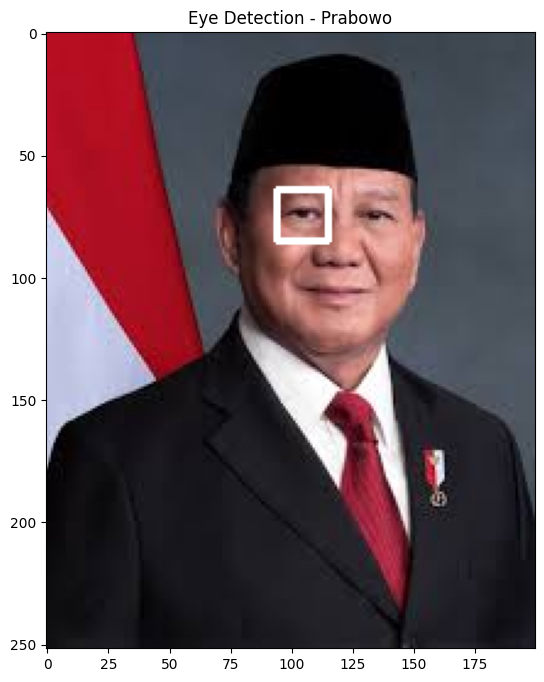

In [67]:
# Menampilkan hasil akhir
plt.figure(figsize=(7, 8))

plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Eye Detection - Prabowo')
plt.axis('on')

plt.show()

 Lakukan deteksi senyuman pada gambar people:

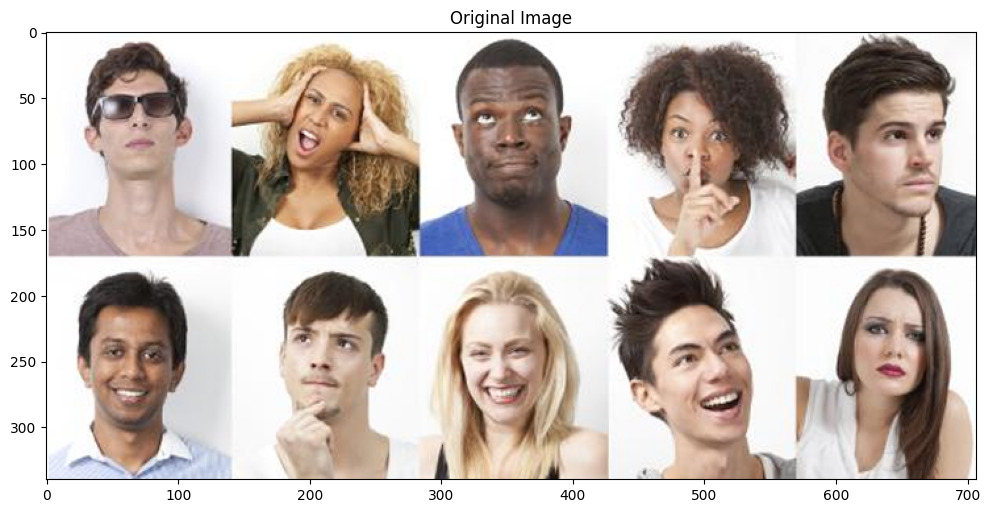

In [68]:
# Membaca gambar
image_path = '/content/drive/MyDrive/Google Collab/Senyum.png'

img = cv.imread(image_path)

# Memeriksa gambar
if img is None:
    raise ValueError("Gambar tidak ditemukan!")

# Mengubah gambar menjadi grayscale
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Menampilkan gambar asli
plt.figure(figsize=(12, 7))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.show()

In [69]:
# Memuat pretrained Haar Cascade untuk wajah
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# Memuat pretrained Haar Cascade untuk senyuman
smile_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_smile.xml'
)

# Memeriksa model
if face_cascade.empty():
    raise ValueError("Gagal memuat Face Cascade!")

if smile_cascade.empty():
    raise ValueError("Gagal memuat Smile Cascade!")

print("Pretrained Haar Cascade berhasil dimuat!")

Pretrained Haar Cascade berhasil dimuat!


In [70]:
# Fungsi Smile Detection
def smile_detection(img):

    # Mengubah gambar menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Mendeteksi wajah
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    # Membuat salinan gambar
    result = img.copy()

    # Menghitung jumlah senyuman
    total_smiles = 0

    # Melakukan deteksi senyuman pada setiap wajah
    for (x, y, w, h) in faces:

        # Mengambil area wajah bagian bawah
        roi_gray = gray[
            y + h // 2:y + h,
            x:x + w
        ]

        # Mengambil area gambar berwarna
        roi_color = result[
            y + h // 2:y + h,
            x:x + w
        ]

        # Mendeteksi senyuman
        smiles = smile_cascade.detectMultiScale(
            roi_gray,
            scaleFactor=1.7,
            minNeighbors=20,
            minSize=(20, 20)
        )

        # Menggambar rectangle pada senyuman
        for (sx, sy, sw, sh) in smiles:

            cv.rectangle(
                roi_color,
                (sx, sy),
                (sx + sw, sy + sh),
                (0, 255, 0),
                2
            )

            total_smiles += 1

    return result, faces, total_smiles

In [71]:
# Fungsi menampilkan hasil Smile Detection
def show_result(img, result, faces, total_smiles):

    plt.figure(figsize=(15, 7))

    # Gambar asli
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.axis('on')

    # Gambar hasil deteksi
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title('Smile Detection')
    plt.axis('on')

    plt.tight_layout()
    plt.show()

    print("Jumlah wajah terdeteksi:", len(faces))
    print("Jumlah senyuman terdeteksi:", total_smiles)

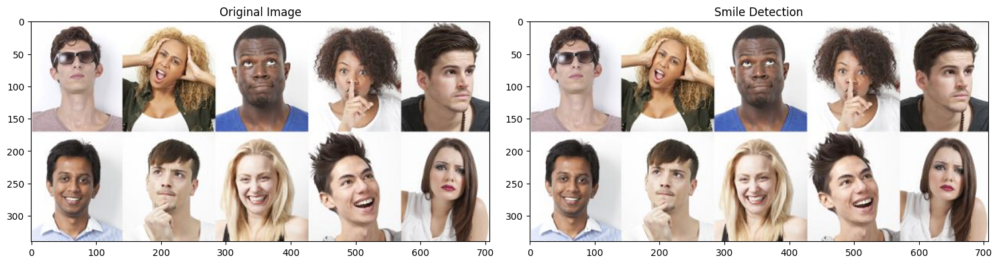

Jumlah wajah terdeteksi: 9
Jumlah senyuman terdeteksi: 0


In [72]:
# Menjalankan Smile Detection
result, faces, total_smiles = smile_detection(img)

# Menampilkan hasil
show_result(
    img,
    result,
    faces,
    total_smiles
)

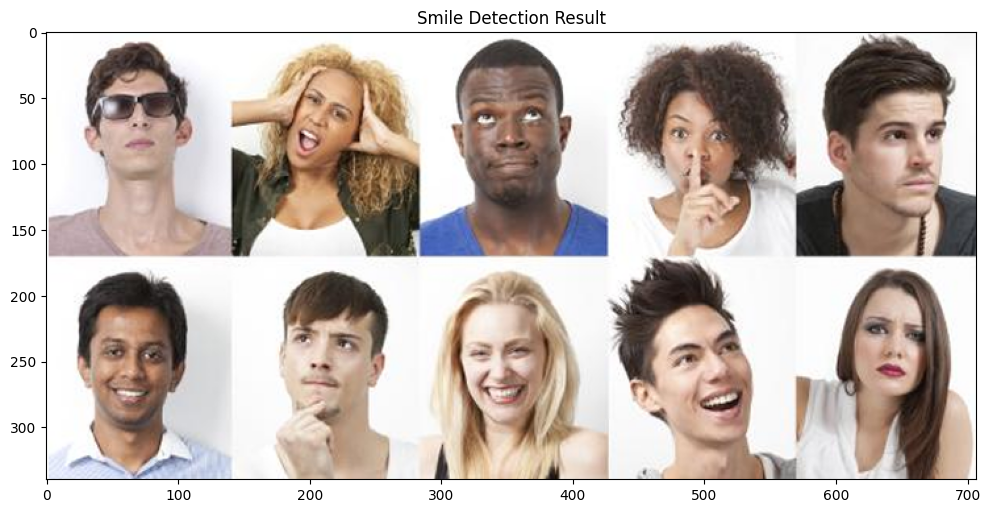

In [73]:
# Menampilkan hasil akhir Smile Detection
plt.figure(figsize=(12, 7))

plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Smile Detection Result')
plt.axis('on')

plt.show()

 Lakukan Blurring pada bagian wajah yang terdeteksi. Berikut contoh keluaran yang diharapkan. Petunjuk: anda dapat menggunakan cv.medianBlur untuk melakukan Blurring

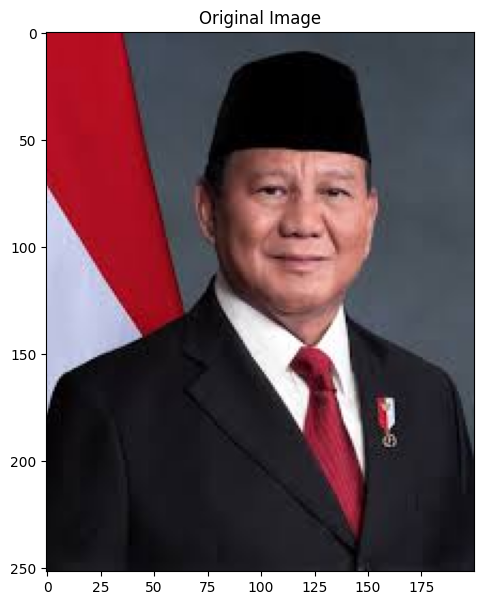

In [74]:
# Membaca gambar
image_path = '/content/drive/MyDrive/Google Collab/Prabowo.jpeg'

img = cv.imread(image_path)

# Memeriksa gambar
if img is None:
    raise ValueError("Gambar tidak ditemukan!")

# Menampilkan gambar asli
plt.figure(figsize=(8, 7))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('on')

plt.show()

In [75]:
# Memuat pretrained Haar Cascade untuk wajah
face_cascade = cv.CascadeClassifier(
    cv.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# Memeriksa model
if face_cascade.empty():
    raise ValueError("Gagal memuat Haar Cascade!")

print("Face Cascade berhasil dimuat!")

Face Cascade berhasil dimuat!


In [76]:
# Fungsi Face Detection
def face_detection(img):

    # Mengubah gambar menjadi grayscale
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Mendeteksi wajah
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    return faces

In [77]:
# Fungsi Face Blurring
def face_blurring(img, faces):

    # Membuat salinan gambar
    result = img.copy()

    # Melakukan blur pada setiap wajah
    for (x, y, w, h) in faces:

        # Mengambil area wajah
        face = result[y:y+h, x:x+w]

        # Melakukan Median Blur
        blurred_face = cv.medianBlur(
            face,
            51
        )

        # Mengganti area wajah dengan hasil blur
        result[y:y+h, x:x+w] = blurred_face

    return result

In [78]:
# Fungsi menampilkan hasil Face Blurring
def show_result(img, result, faces):

    plt.figure(figsize=(12, 7))

    # Gambar asli
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Original Image')
    plt.axis('on')

    # Gambar hasil blur
    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    plt.title('Face Blurring')
    plt.axis('on')

    plt.tight_layout()
    plt.show()

    print("Jumlah wajah terdeteksi:", len(faces))

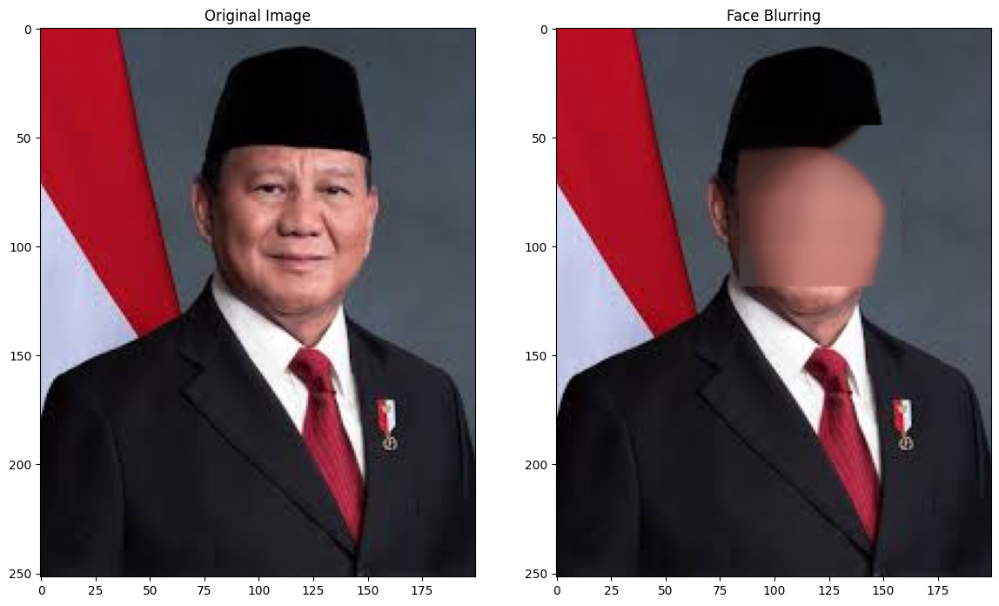

Jumlah wajah terdeteksi: 1


In [79]:
# Mendeteksi wajah
faces = face_detection(img)

# Melakukan blurring pada wajah
result = face_blurring(img, faces)

# Menampilkan hasil
show_result(img, result, faces)

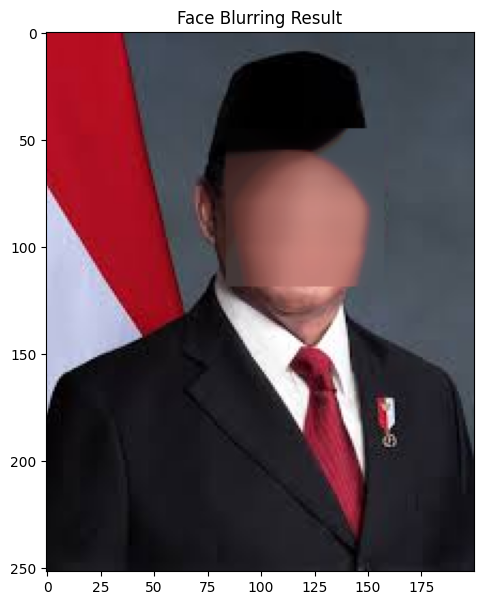

In [80]:
# Menampilkan hasil Face Blurring
plt.figure(figsize=(8, 7))

plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title('Face Blurring Result')
plt.axis('on')

plt.show()

Mengolah gambar KTM masing-masing

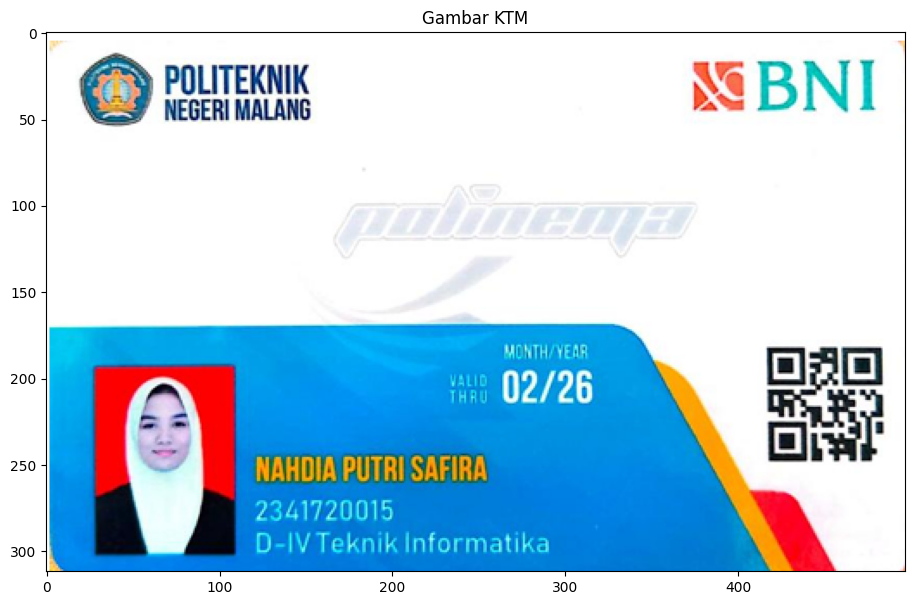

In [81]:
# Membaca gambar KTM
image_path = '/content/drive/MyDrive/Google Collab/ktmm.png'

img = cv.imread(image_path)

# Memeriksa gambar
if img is None:
    raise ValueError("Gambar KTM tidak ditemukan!")

# Menampilkan gambar KTM
plt.figure(figsize=(12, 7))

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.title('Gambar KTM')
plt.axis('on')

plt.show()

In [82]:
# Fungsi Crop Foto KTM
def crop_foto_ktm(img, x, y, w, h):

    # Mengambil area foto KTM
    foto = img[y:y+h, x:x+w]

    return foto

In [91]:
# Menentukan koordinat foto KTM
x = 27
y = 193
w = 82
h = 111

# Melakukan crop foto KTM
foto_ktm = crop_foto_ktm(img, x, y, w, h)

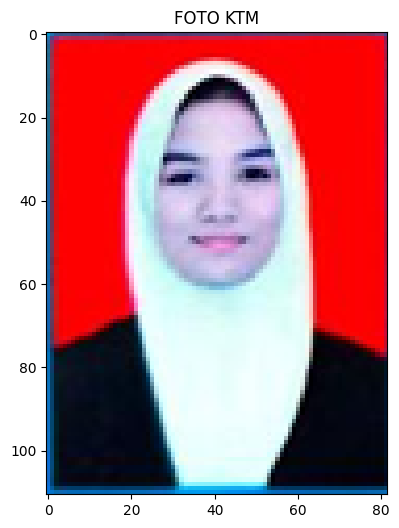

In [92]:
# Menampilkan hasil crop foto KTM
plt.figure(figsize=(5, 6))

plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB))
plt.title('FOTO KTM')
plt.axis('on')

plt.show()

# Tugas Pengayaan : Pengenalan Karakter KTM dengan CNN

In [93]:
!pip install kagglehub

In [94]:
import kagglehub

# Download dataset EMNIST
path = kagglehub.dataset_download("crawford/emnist")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'emnist' dataset.
Path to dataset files: /kaggle/input/emnist


In [95]:
import os

for root, dirs, files in os.walk(path):
    print("Folder:", root)
    print("File:", files[:10])
    print("-" * 50)

Folder: /kaggle/input/emnist
File: ['emnist-letters-mapping.txt', 'emnist-letters-test.csv', 'emnist-mnist-mapping.txt', 'emnist-digits-train.csv', 'emnist-bymerge-mapping.txt', 'emnist-balanced-train.csv', 'emnist-digits-test.csv', 'emnist-balanced-test.csv', 'emnist-mnist-test.csv', 'emnist-letters-train.csv']
--------------------------------------------------
Folder: /kaggle/input/emnist/emnist_source_files
File: ['emnist-digits-test-labels-idx1-ubyte', 'emnist-bymerge-train-labels-idx1-ubyte', 'emnist-letters-test-labels-idx1-ubyte', 'emnist-byclass-train-images-idx3-ubyte', 'emnist-byclass-test-images-idx3-ubyte', 'emnist-mnist-train-images-idx3-ubyte', 'emnist-digits-train-labels-idx1-ubyte', 'emnist-bymerge-test-images-idx3-ubyte', 'emnist-bymerge-test-labels-idx1-ubyte', 'emnist-mnist-test-labels-idx1-ubyte']
--------------------------------------------------


In [96]:
import os

for file in os.listdir(path):
    if "byclass-train" in file:
        print(file)

emnist-byclass-train.csv


In [97]:
import os
import cv2
import numpy as np
import pandas as pd
import string
from tqdm import tqdm

# Lokasi file CSV
csv_path = os.path.join(path, "emnist-byclass-train.csv")

# Lokasi penyimpanan gambar
OUTPUT_DIR = "dataset/training"

# Nama kelas: 0-9 dan A-Z
class_names = [str(i) for i in range(10)] + list(string.ascii_uppercase)

# Maksimal gambar per kelas
MAX_PER_CLASS = 1000

# Buat folder setiap kelas
for name in class_names:
    os.makedirs(os.path.join(OUTPUT_DIR, name), exist_ok=True)

# Menghitung jumlah gambar setiap kelas
counts = {i: 0 for i in range(36)}

# Membaca CSV secara bertahap agar RAM tidak cepat penuh
for chunk in tqdm(
    pd.read_csv(csv_path, header=None, chunksize=1000),
    desc="Konversi dataset"
):
    for _, row in chunk.iterrows():

        label = int(row.iloc[0])

        # Hanya mengambil kelas 0-35
        if label >= 36:
            continue

        # Lewati jika jumlah gambar kelas sudah mencapai batas
        if counts[label] >= MAX_PER_CLASS:
            continue

        # Ambil 784 pixel dan ubah menjadi gambar 28x28
        image = row.iloc[1:].to_numpy(dtype=np.uint8).reshape(28, 28)

        # Koreksi orientasi gambar EMNIST
        image = np.fliplr(np.rot90(image, k=3))

        # Tentukan nama folder berdasarkan label
        class_name = class_names[label]

        # Nama file gambar
        filename = f"{counts[label]}.png"

        # Simpan gambar
        save_path = os.path.join(
            OUTPUT_DIR,
            class_name,
            filename
        )

        cv2.imwrite(save_path, image)

        counts[label] += 1

print("Konversi selesai!")
print("Total gambar:", sum(counts.values()))
print("Jumlah kelas:", len(class_names))

Konversi dataset: 698it [01:51,  6.23it/s]

Konversi selesai!
Total gambar: 36000
Jumlah kelas: 36


In [101]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "/content/dataset/training"
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    folder_path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)

    for img in tqdm(os.listdir(folder_path), desc=char_name):
        try:
            img_array = cv2.imread(
                os.path.join(folder_path, img),
                cv2.IMREAD_GRAYSCALE
            )

            if img_array is None:
                continue

            new_array = cv2.resize(img_array, (width, height))
            training_data.append([new_array, class_number])

        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []

for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

# Simpan di Google Colab (/content)
pickle.dump(X, open("/content/X.pickle", "wb"))
pickle.dump(Y, open("/content/Y.pickle", "wb"))
pickle.dump(dirs, open("/content/kelas.pickle", "wb"))

print("Jumlah data:", len(training_data))
print("Shape X:", X.shape)
print("Shape Y:", Y.shape)
print("Preprocessing selesai!")

Z: 100%|██████████| 1000/1000 [00:00<00:00, 5757.95it/s]


Jumlah data: 36000
Shape X: (36000, 100, 100, 1)
Shape Y: (36000,)
Preprocessing selesai!


In [102]:
import os

print("X.pickle:", os.path.exists("/content/X.pickle"))
print("Y.pickle:", os.path.exists("/content/Y.pickle"))
print("kelas.pickle:", os.path.exists("/content/kelas.pickle"))

X.pickle: True
Y.pickle: True
kelas.pickle: True


In [103]:
import pickle
import numpy as np

from tensorflow.keras.utils import to_categorical

# Load dataset
X = pickle.load(open("/content/X.pickle", "rb"))
Y = pickle.load(open("/content/Y.pickle", "rb"))

# Normalisasi
X = X.astype("float32") / 255.0

# One-hot encoding
Y = to_categorical(Y)

width, height = 100, 100
jumlah_kelas = Y.shape[1]

print("Shape X:", X.shape)
print("Shape Y:", Y.shape)
print("Jumlah kelas:", jumlah_kelas)

Shape X: (36000, 100, 100, 1)
Shape Y: (36000, 36)
Jumlah kelas: 36


In [104]:
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, ZeroPadding2D
)

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

inputs = Input(shape=(width, height, 1))

conv_layer = ZeroPadding2D(padding=(1, 1))(inputs)

conv_layer = Conv2D(16, (5, 5), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(32, (3, 3), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)

conv_layer = Conv2D(64, (3, 3), activation='relu')(conv_layer)

flatten = Flatten()(conv_layer)

fc_layer = Dense(256, activation='relu')(flatten)
fc_layer = Dense(64, activation='relu')(fc_layer)

outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 100, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ zero_padding2d (ZeroPadding2D)  │ (None, 102, 102, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 98, 98, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,553,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,605,444 (25.20 MB)

 Trainable params: 6,605,444 (25.20 MB)

 Non-trainable params: 0 (0.00 B)

In [105]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [106]:
riwayat = model.fit(
    X,
    Y,
    epochs=20,
    verbose=1,
    validation_split=0.2
)

Epoch 1/20
900/900 ━━━━━━━━━━━━━━━━━━━━ 492s 544ms/step - accuracy: 0.6951 - loss: 1.0856 - val_accuracy: 0.8394 - val_loss: 0.5215
Epoch 2/20
900/900 ━━━━━━━━━━━━━━━━━━━━ 490s 531ms/step - accuracy: 0.8721 - loss: 0.4032 - val_accuracy: 0.8689 - val_loss: 0.4143
Epoch 3/20


KeyboardInterrupt: 

In [ ]:
model.save("/content/ampr.keras")

print("Model berhasil disimpan!")

In [ ]:
print("Akurasi training:", riwayat.history['accuracy'][-1])
print("Akurasi validasi:", riwayat.history['val_accuracy'][-1])